Loaded 28108 listings, 18 columns.


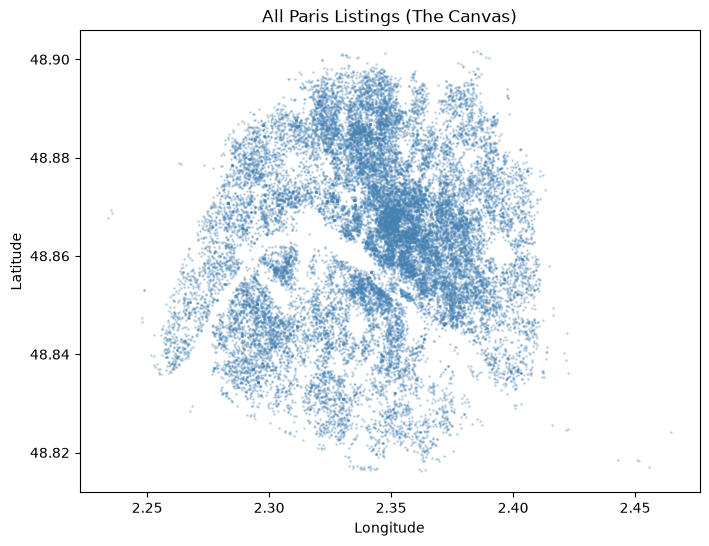

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.vq import kmeans2

df = pd.read_csv("paris_listings.csv")
print(f"Loaded {len(df)} listings, {df.shape[1]} columns.")

plt.figure(figsize=(8, 6))
plt.scatter(df["longitude"], df["latitude"], s=1, alpha=0.25, c="steelblue")
plt.title("All Paris Listings (The Canvas)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

Found 1 grey dots.


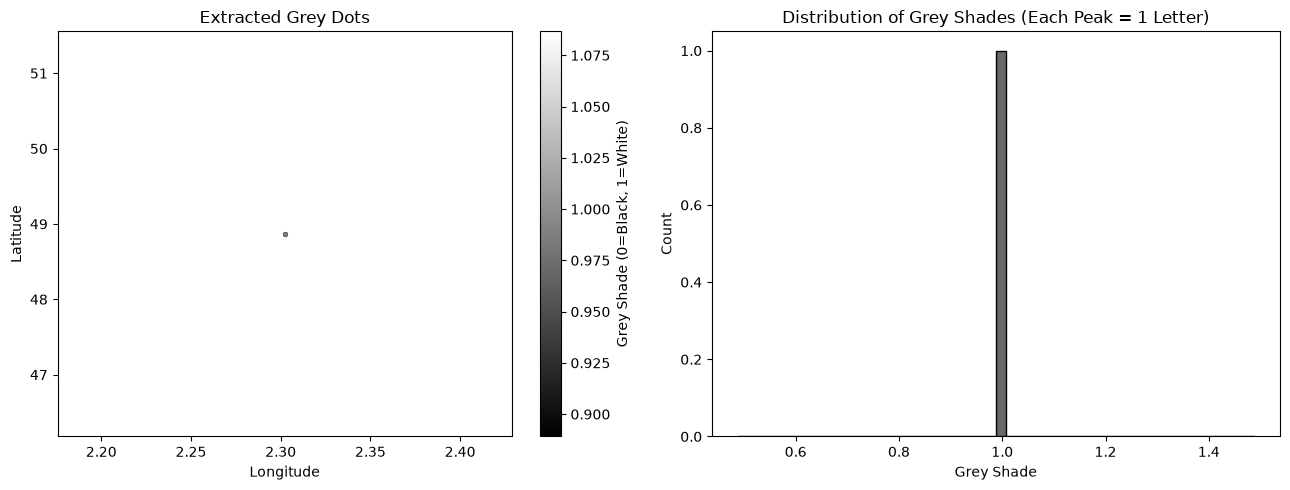

In [14]:
# "Their colours came from what every traveller weighs before booking a night."
# "Grey is pretty. It holds multiple secrets."
rgb_cols = ["price", "availability_365", "review_scores_rating"]

# Min-Max scale each channel to [0, 1] using pure pandas/numpy (no sklearn needed)
col_min = df[rgb_cols].min()
col_max = df[rgb_cols].max()
scaled_rgb = ((df[rgb_cols] - col_min) / (col_max - col_min)).to_numpy()

# Compute spread between R, G, B channels for each listing
channel_spread = np.nanmax(scaled_rgb, axis=1) - np.nanmin(scaled_rgb, axis=1)
grey_shade = np.nanmean(scaled_rgb, axis=1)

# Filter for grey dots where R ≈ G ≈ B (adjust tolerance if needed, e.g., 0.01 - 0.05)
tolerance = 0.02
is_grey = (channel_spread < tolerance) & (grey_shade > 0.01) & (grey_shade < 0.99)

grey_dots_rgb = df[is_grey].copy()
grey_dots_rgb["grey_shade"] = grey_shade[is_grey]

print(f"Found {len(grey_dots_rgb)} grey dots.")

# Plot the grey dots and their shade histogram
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc = axes[0].scatter(
    grey_dots_rgb["longitude"],
    grey_dots_rgb["latitude"],
    c=grey_dots_rgb["grey_shade"],
    cmap="gray",
    s=12,
    edgecolor="black",
    linewidth=0.3,
)
plt.colorbar(sc, ax=axes[0], label="Grey Shade (0=Black, 1=White)")
axes[0].set_title("Extracted Grey Dots")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

axes[1].hist(grey_dots_rgb["grey_shade"], bins=50, color="dimgray", edgecolor="black")
axes[1].set_title("Distribution of Grey Shades (Each Peak = 1 Letter)")
axes[1].set_xlabel("Grey Shade")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

In [ ]:
# Set n_letters to the number of peaks seen in the histogram above
n_letters = 6

shades = grey_dots_rgb[["grey_shade"]].to_numpy(dtype=float)
if len(shades) == 0:
    grey_dots_rgb["letter_cluster"] = pd.Series(dtype=int)
    print("No grey dots found to cluster; adjust rgb_cols, scaling, or tolerance.")
else:
    k = min(n_letters, len(shades))
    if k < n_letters:
        print(f"Warning: found only {len(shades)} grey dot(s) (< n_letters={n_letters}); clustering with k={k}.")
    centroids, raw_labels = kmeans2(shades, k=k, minit="points", rng=42)

    # Order clusters from darkest (0) to lightest (k - 1)
    order = np.argsort(centroids.flatten())
    rank_map = {old_lbl: new_lbl for new_lbl, old_lbl in enumerate(order)}
    grey_dots_rgb["letter_cluster"] = [rank_map[lbl] for lbl in raw_labels]

    # Plot each cluster side-by-side to read the hidden word
    fig, axes = plt.subplots(1, k, figsize=(3.2 * k, 3.5), squeeze=False)
    axes = axes[0]
    for i in range(k):
        sub = grey_dots_rgb[grey_dots_rgb["letter_cluster"] == i]
        axes[i].scatter(sub["longitude"], sub["latitude"], s=20, c="black")
        axes[i].set_title(f"Letter {i+1}\n(shade={centroids[order[i]][0]:.3f})")
        axes[i].set_aspect("equal", adjustable="datalim")
        axes[i].set_xticks([])
        axes[i].set_yticks([])

    plt.suptitle("Hidden Word Letters (Ordered by Grey Shade)", fontsize=14)
    plt.tight_layout()
    plt.savefig("clustered_word.png", dpi=200)
    plt.show()
    print("Saved figure to clustered_word.png")

In [ ]:
# Assign -1 to background city listings, and 0..(n_letters-1) to each letter
df["label"] = -1
df.loc[grey_dots_rgb.index, "label"] = grey_dots_rgb["letter_cluster"]

df[["listing_id", "label"]].to_csv("labels.csv", index=False)
print("Saved labels.csv successfully!")
print(df["label"].value_counts().sort_index())

# Replace <WORD> below once you read the letters from the plot:
WORD = "YOUR_WORD_HERE"
print(f"FLAG: SIGMOID_{WORD}")